# Level 2 · Task 2 — Decision Trees for Classification
**Codveda Technology — Machine Learning Internship**

**Goal:** build a decision tree that predicts the **species of an iris flower** from its measurements.

**Dataset:** `iris.csv` — 150 flowers, 4 features, 3 balanced classes.

**Objectives covered**
1. Train a decision tree on a labeled dataset (Iris)
2. Visualize the tree structure
3. Prune the tree to prevent overfitting (pre-pruning with `max_depth` and post-pruning with cost-complexity `ccp_alpha`)
4. Evaluate with accuracy and F1-score

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load the data & split
Decision trees split on one feature at a time using thresholds, so **no scaling is needed**.

In [2]:
df = pd.read_csv(DATA / "iris.csv")
X = df.drop(columns="species")
y = df["species"]
class_names = sorted(y.unique())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print(y_train.value_counts().to_dict())

Train: (105, 4) | Test: (45, 4)
{'versicolor': 35, 'setosa': 35, 'virginica': 35}


## 2. Fully-grown (unpruned) tree
With no limits the tree keeps splitting until every leaf is pure — it memorises the training data.

In [3]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)

def evaluate(model, name):
    tr, te = model.predict(X_train), model.predict(X_test)
    return {"Model": name, "Depth": model.get_depth(), "Leaves": model.get_n_leaves(),
            "Train accuracy": accuracy_score(y_train, tr), "Test accuracy": accuracy_score(y_test, te),
            "Test F1 (macro)": f1_score(y_test, te, average="macro")}

pd.DataFrame([evaluate(full_tree, "Unpruned tree")]).round(3)

,Model,Depth,Leaves,Train accuracy,Test accuracy,Test F1 (macro)
0,Unpruned tree,5,8,1.0,0.933,0.933


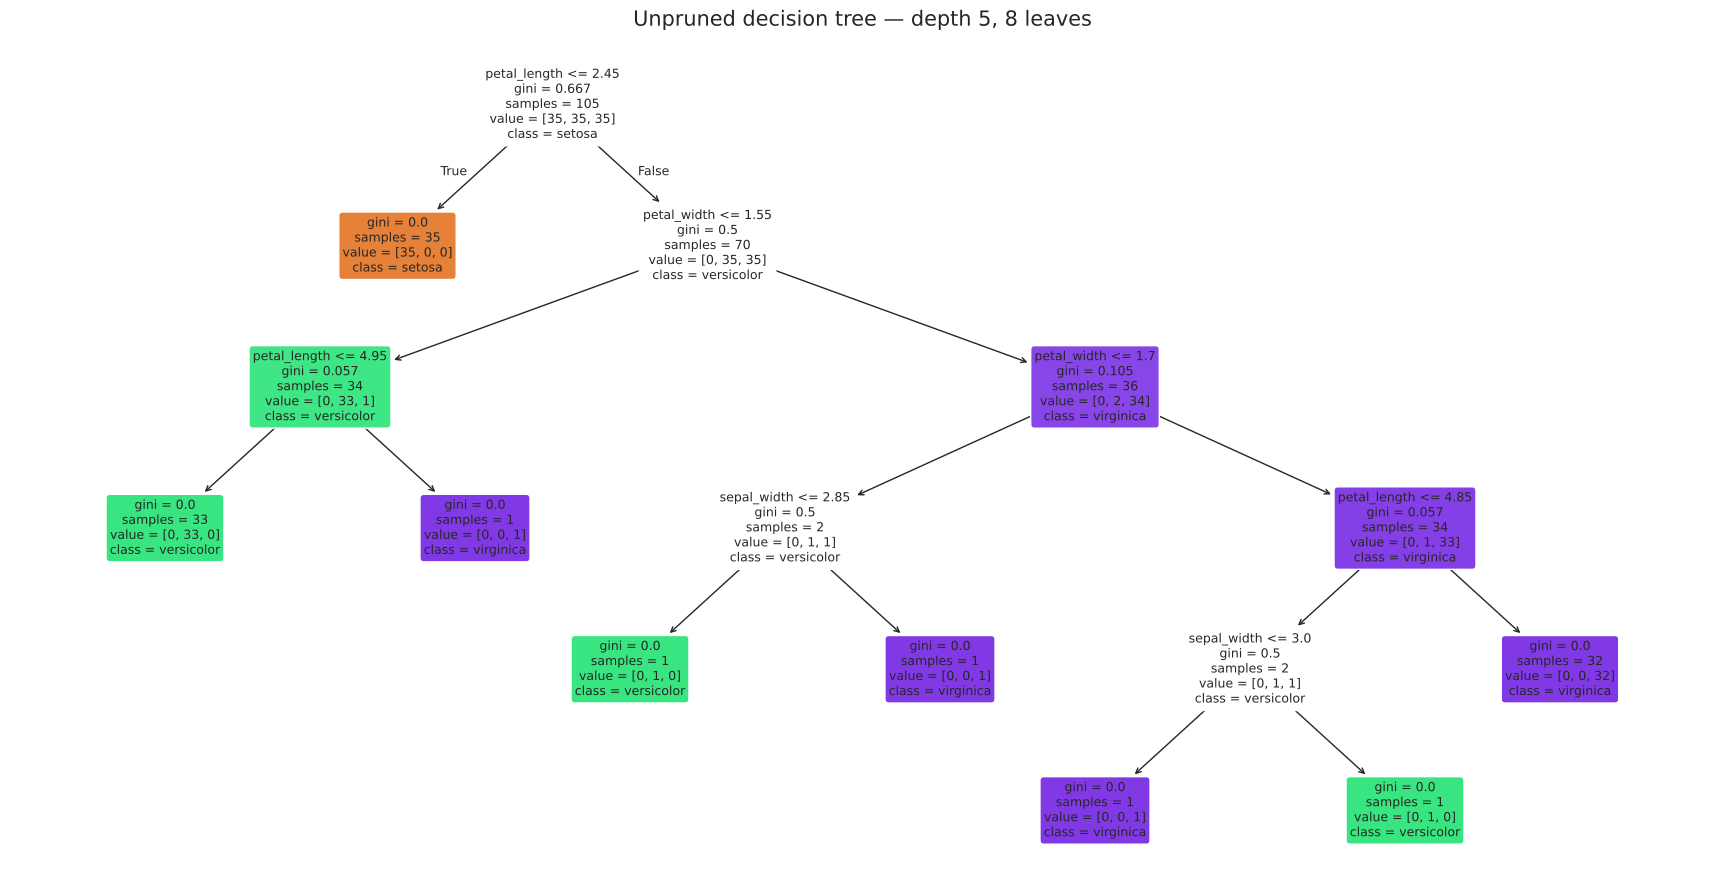

In [4]:
fig, ax = plt.subplots(figsize=(22, 11))
plot_tree(full_tree, feature_names=X.columns, class_names=class_names, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f"Unpruned decision tree — depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves", fontsize=15)
plt.savefig(IMG / "tree_unpruned.png", dpi=100, bbox_inches="tight"); plt.show()

The lower branches split on tiny differences (e.g. 0.05 cm) to isolate one or two flowers — a typical sign of **overfitting**.

## 3. Pruning
### 3a. Pre-pruning — limit the depth
We compare `max_depth` = 1 … 8 using 10-fold cross-validation on the training set.

In [5]:
cv = StratifiedKFold(10, shuffle=True, random_state=RANDOM_STATE)
depth_rows = []
for d in range(1, 9):
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    s = cross_val_score(m, X_train, y_train, cv=cv)
    m.fit(X_train, y_train)
    depth_rows.append({"max_depth": d, "train_acc": m.score(X_train, y_train), "cv_acc": s.mean(), "cv_std": s.std(),
                       "test_acc": m.score(X_test, y_test)})
depth_df = pd.DataFrame(depth_rows)
depth_df.round(3)

,max_depth,train_acc,cv_acc,cv_std,test_acc
0,1,0.667,0.668,0.032,0.667
1,2,0.971,0.944,0.074,0.889
2,3,0.981,0.954,0.074,0.978
3,4,0.990,0.954,0.074,0.889
4,5,1.000,0.954,0.074,0.933
5,6,1.000,0.954,0.074,0.933
6,7,1.000,0.954,0.074,0.933
7,8,1.000,0.954,0.074,0.933


### 3b. Post-pruning — cost-complexity pruning (`ccp_alpha`)
scikit-learn computes the sequence of "weakest links": each `ccp_alpha` value removes the branches whose
accuracy gain is smallest relative to the extra complexity. Bigger alpha → smaller tree.

In [6]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]          # the last alpha collapses the tree to a single node
alpha_rows = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    s = cross_val_score(m, X_train, y_train, cv=cv)
    m.fit(X_train, y_train)
    alpha_rows.append({"ccp_alpha": a, "leaves": m.get_n_leaves(), "depth": m.get_depth(),
                       "train_acc": m.score(X_train, y_train), "cv_acc": s.mean(), "test_acc": m.score(X_test, y_test)})
alpha_df = pd.DataFrame(alpha_rows)
alpha_df.round(4)

,ccp_alpha,leaves,depth,train_acc,cv_acc,test_acc
0,0.0000,8,5,1.0000,0.9536,0.9333
1,0.0090,4,3,0.9810,0.9536,0.9333
2,0.0185,3,2,0.9714,0.9536,0.8889
3,0.2789,2,1,0.6667,0.7245,0.6667


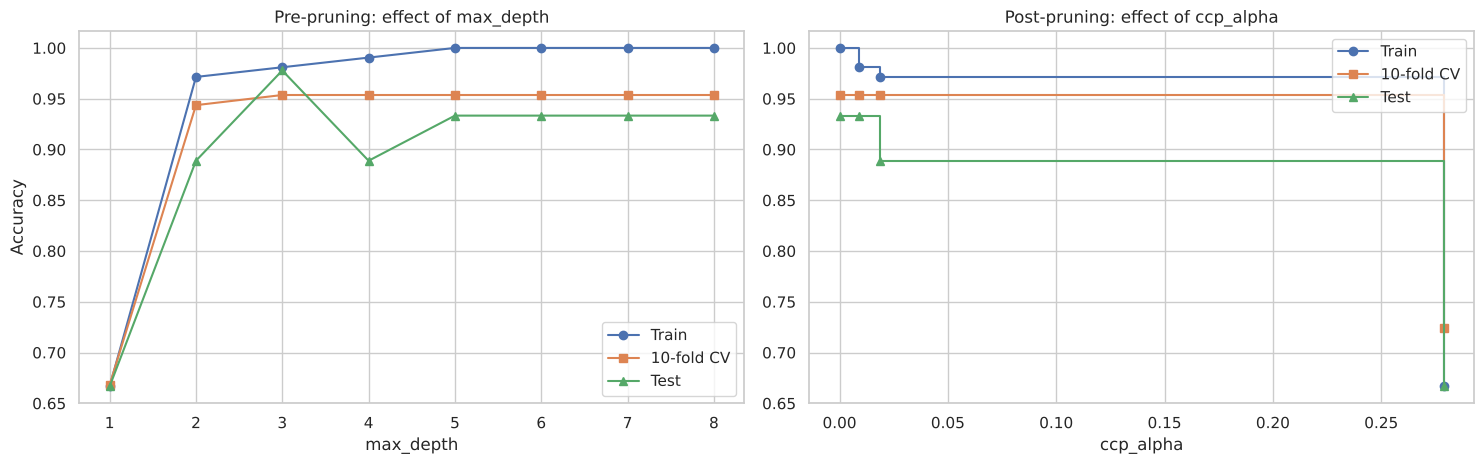

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(depth_df["max_depth"], depth_df["train_acc"], "o-", label="Train")
axes[0].plot(depth_df["max_depth"], depth_df["cv_acc"], "s-", label="10-fold CV")
axes[0].plot(depth_df["max_depth"], depth_df["test_acc"], "^-", label="Test")
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("Accuracy"); axes[0].set_title("Pre-pruning: effect of max_depth"); axes[0].legend()
axes[1].plot(alpha_df["ccp_alpha"], alpha_df["train_acc"], "o-", drawstyle="steps-post", label="Train")
axes[1].plot(alpha_df["ccp_alpha"], alpha_df["cv_acc"], "s-", drawstyle="steps-post", label="10-fold CV")
axes[1].plot(alpha_df["ccp_alpha"], alpha_df["test_acc"], "^-", drawstyle="steps-post", label="Test")
axes[1].set_xlabel("ccp_alpha"); axes[1].set_title("Post-pruning: effect of ccp_alpha"); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG / "pruning_curves.png", dpi=120); plt.show()

### 3c. Choose the final pruned tree (cross-validation only — the test set is untouched)
* Depth 1–2 **underfit** (CV accuracy 0.67 / 0.94).
* From depth 3 upward the CV accuracy stops improving (0.954) while training accuracy climbs to 100 % → extra depth only memorises noise.
* Rule: take the **smallest depth that reaches the best CV accuracy** → `max_depth = 3`.

Cost-complexity pruning tells the same story: with `ccp_alpha ≈ 0.009` the tree also shrinks to depth 3 with 4 leaves and the
same CV accuracy as the full tree.

In [8]:
best_cv = depth_df["cv_acc"].max()
best_depth = int(depth_df.loc[depth_df["cv_acc"] >= best_cv - 1e-9, "max_depth"].min())
print(f"Best CV accuracy {best_cv:.3f} first reached at max_depth = {best_depth}")

pruned = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE).fit(X_train, y_train)
ccp_tree = DecisionTreeClassifier(ccp_alpha=alphas[1], random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Pre-pruned  (max_depth={best_depth})      → depth {pruned.get_depth()}, {pruned.get_n_leaves()} leaves")
print(f"Post-pruned (ccp_alpha={alphas[1]:.4f}) → depth {ccp_tree.get_depth()}, {ccp_tree.get_n_leaves()} leaves")

Best CV accuracy 0.954 first reached at max_depth = 3
Pre-pruned  (max_depth=3)      → depth 3, 5 leaves
Post-pruned (ccp_alpha=0.0090) → depth 3, 4 leaves


## 4. Visualize the pruned tree

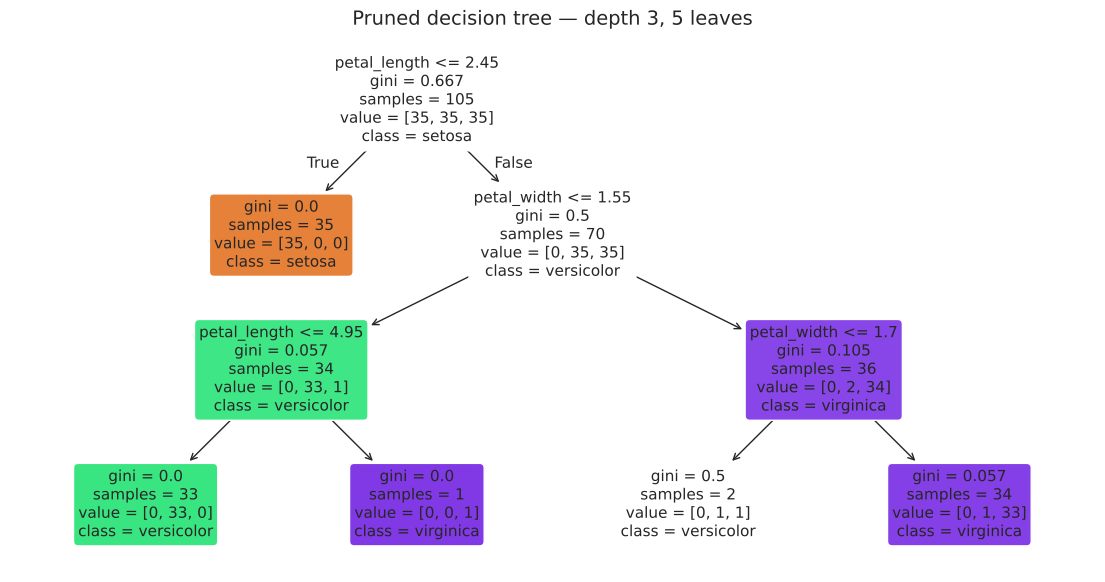

In [9]:
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(pruned, feature_names=X.columns, class_names=class_names, filled=True, rounded=True, fontsize=11, ax=ax)
ax.set_title(f"Pruned decision tree — depth {pruned.get_depth()}, {pruned.get_n_leaves()} leaves", fontsize=14)
plt.savefig(IMG / "tree_pruned.png", dpi=120, bbox_inches="tight"); plt.show()

In [10]:
print(export_text(pruned, feature_names=list(X.columns)))

|--- petal_length <= 2.45
|   |--- class: setosa
|--- petal_length >  2.45
|   |--- petal_width <= 1.55
|   |   |--- petal_length <= 4.95
|   |   |   |--- class: versicolor
|   |   |--- petal_length >  4.95
|   |   |   |--- class: virginica
|   |--- petal_width >  1.55
|   |   |--- petal_width <= 1.70
|   |   |   |--- class: versicolor
|   |   |--- petal_width >  1.70
|   |   |   |--- class: virginica



## 5. Evaluation — unpruned vs pruned

In [11]:
summary = pd.DataFrame([evaluate(full_tree, "Unpruned tree"),
                        evaluate(pruned, f"Pre-pruned (max_depth={best_depth})"),
                        evaluate(ccp_tree, "Post-pruned (ccp_alpha)")])
summary["10-fold CV accuracy"] = [cross_val_score(m, X_train, y_train, cv=cv).mean() for m in [full_tree, pruned, ccp_tree]]
summary.round(3)

,Model,Depth,Leaves,Train accuracy,Test accuracy,Test F1 (macro),10-fold CV accuracy
0,Unpruned tree,5,8,1.000,0.933,0.933,0.954
1,Pre-pruned (max_depth=3),3,5,0.981,0.978,0.978,0.954
2,Post-pruned (ccp_alpha),3,4,0.981,0.933,0.933,0.954


In [12]:
print(classification_report(y_test, pruned.predict(X_test), digits=3))

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      1.000     0.933     0.966        15
   virginica      0.938     1.000     0.968        15

    accuracy                          0.978        45
   macro avg      0.979     0.978     0.978        45
weighted avg      0.979     0.978     0.978        45



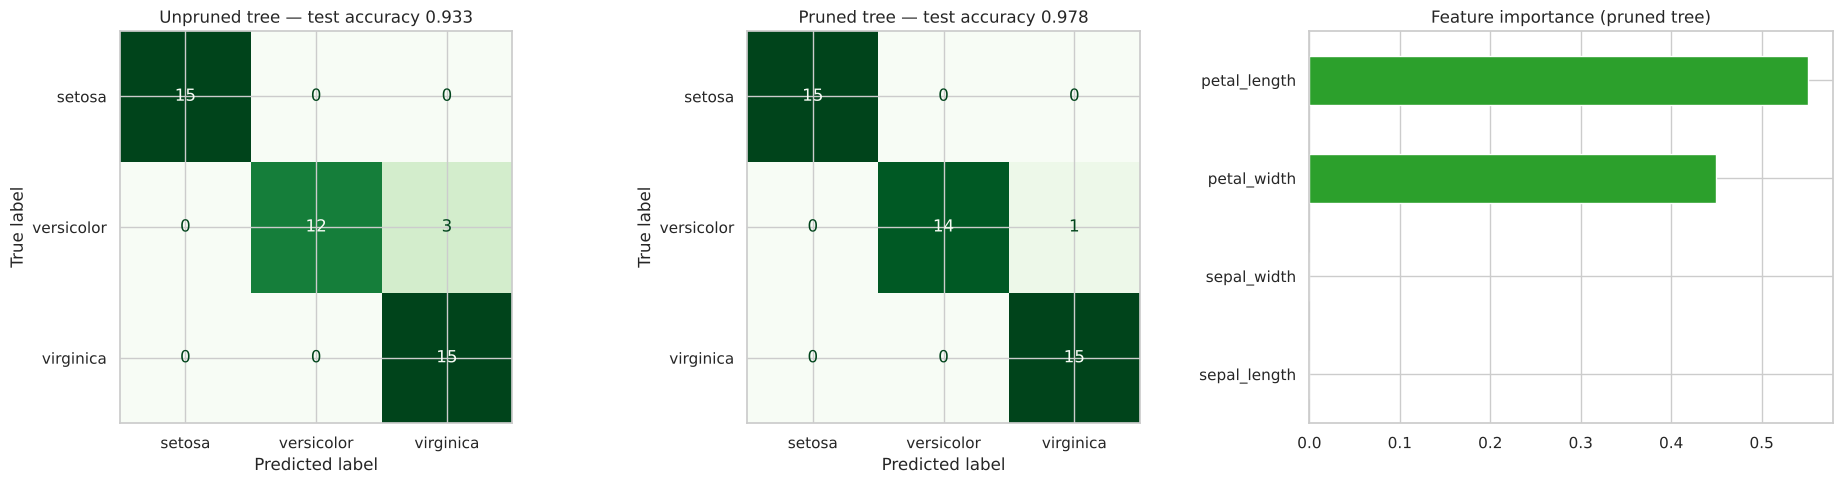

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (m, n) in zip(axes[:2], [(full_tree, "Unpruned"), (pruned, "Pruned")]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, cmap="Greens", colorbar=False, ax=ax)
    ax.set_title(f"{n} tree — test accuracy {m.score(X_test, y_test):.3f}")
imp = pd.Series(pruned.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=axes[2], color="tab:green"); axes[2].set_title("Feature importance (pruned tree)")
plt.tight_layout(); plt.savefig(IMG / "evaluation.png", dpi=120); plt.show()

## Conclusions
| Model | Depth | Leaves | Train acc | Test acc | Test F1 (macro) | CV acc |
|---|---|---|---|---|---|---|
| Unpruned | 5 | 8 | 1.000 | 0.933 | 0.933 | 0.954 |
| **Pre-pruned (max_depth = 3)** | 3 | 5 | 0.981 | **0.978** | **0.978** | 0.954 |
| Post-pruned (ccp_alpha ≈ 0.009) | 3 | 4 | 0.981 | 0.933 | 0.933 | 0.954 |

* The **unpruned tree overfits**: 100 % training accuracy, 8 leaves, and splits that isolate single flowers.
* **Pruning keeps the same cross-validated accuracy with a much simpler tree** (4–5 leaves instead of 8). The depth-3 tree
  also scores best on the test set (97.8 % accuracy, F1 = 0.978 — only 1 of 45 flowers misclassified).
* The tree is easy to read: **petal length ≤ 2.45 cm → setosa**; otherwise **petal width ≤ 1.55 cm → mostly versicolor**, wider → virginica.
  Petal measurements carry almost all the importance; sepal features are not used at all.
* Note: the test set has only 45 flowers (1 flower = 2.2 %), so cross-validation — not the test score — was used to choose
  the amount of pruning.